# NVIDIA GPU QAOA

**Версия 0.1.0a6.** Ноутбук проверяет реальный CuPy-путь: диагностику
устройства, full и pair-представления, CPU/GPU-сравнение при фиксированных
углах, все пять критериев, семплер, два readout-режима, GPU-RQAOA и небольшую
GPU-LS задачу.

GPU-среда не обязательна для импорта пакета. Этот ноутбук должен исполняться
с установленным CuPy на NVIDIA-машине.

In [1]:
from pathlib import Path
import json
import tempfile
import numpy as np

import QA_max_cut_lib
from QA_max_cut_lib import (
    GraphFactory, QAOAGPU, QAOAGPUCorrelationSource, RQAOAGPU, LSRQAOAGPU, tools,
)
from QA_max_cut_lib.solvers.gpu_state import (
    gpu_available, gpu_device_info, cut_diagonal_gpu, state_at_angles_gpu,
    restore_full_gpu, correlations_gpu, objective_value_gpu, sample_full_indices_gpu,
)
from QA_max_cut_lib.solvers.qaoa_state import cut_diagonal, state_at_angles
from QA_max_cut_lib.solvers.objectives import validate_objective, objective_value

PROJECT = Path.cwd()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent
print(QA_max_cut_lib.__version__)
print("package:", Path(QA_max_cut_lib.__file__).resolve())
print("gpu_available:", gpu_available())
assert QA_max_cut_lib.__version__ == "0.1.0a6"
assert gpu_available()

0.1.0a6
package: C:\Users\Alexey\PycharmProjects\QA_max_cut_lib\src\QA_max_cut_lib\__init__.py


gpu_available: True


## Диагностика устройства

In [2]:
info = gpu_device_info(0)
print(json.dumps(info, indent=2))
assert info["name"]
assert info["memory_total"] > info["memory_free"]

{
  "device_id": 0,
  "name": "NVIDIA GeForce RTX 3050 Laptop GPU",
  "compute_capability": [
    8,
    6
  ],
  "multiprocessors": 16,
  "memory_free": 3462660096,
  "memory_total": 4294508544,
  "runtime_version": 13020,
  "driver_version": 13010,
  "cupy_version": "14.2.0"
}

## Full и pair-состояния при фиксированных углах

Pair-режим хранит `chi`, а не физический `psi`. Восстановленный полный вектор
сравнивается с CPU-эталоном.

In [3]:
graph = GraphFactory.from_recipe({
    "type": "complete", "seed": 11,
    "parameters": {"n_vertices": 6},
    "weights": {"type": "signed_discrete", "seed": 12, "parameters": {"values": [-2, -1, 1, 2]}},
})
angles = [0.3, 0.2, 0.4, -0.1]
cpu_state, cpu_masses = state_at_angles(cut_diagonal(graph), angles, 2, "complex128")
for representation in ("full", "spin_flip_pairs"):
    gpu_cuts = cut_diagonal_gpu(graph, representation)
    gpu_state, gpu_masses = state_at_angles_gpu(
        gpu_cuts, angles, 2, n_vertices=len(graph),
        representation=representation, dtype="complex128",
    )
    if representation == "full":
        error = float(np.max(np.abs(gpu_state.get() - cpu_state)))
        print("full state error:", error)
        assert error < 1e-11
    else:
        restored = restore_full_gpu(gpu_state, len(graph)).get()
        pair_error = float(np.max(np.abs(restored - cpu_state)))
        print("pair restored error:", pair_error)
        assert pair_error < 1e-11
        assert abs(float(gpu_masses.sum()) - 1) < 1e-11

full state error: 1.7772239894833365e-16
pair restored error: 2.0816681711721685e-16


## Все пять критериев

In [4]:
cuts = np.array([-2.0, 0.0, 1.0, 3.0])
masses = np.array([0.1, 0.2, 0.3, 0.4])
for raw in (
    {"type": "mean_cut", "parameters": {}},
    {"type": "cvar", "parameters": {"alpha": 0.5}},
    {"type": "gibbs", "parameters": {"eta": 1.3}},
    {"type": "best_of_k", "parameters": {"k": 3}},
    {"type": "threshold_probability", "parameters": {"threshold": 1.0}},
):
    criterion = validate_objective(raw)
    expected = objective_value(cuts, masses, criterion)
    actual = objective_value_gpu(cuts, masses, criterion)
    print(criterion["type"], actual, "error", abs(actual - expected))
    assert abs(actual - expected) < 1e-12

mean_cut 1.3000000000000003 error 2.220446049250313e-16
cvar 2.6000000000000005 error 0.0
gibbs 2.3444708219876733 error 0.0
best_of_k 2.539 error 4.440892098500626e-16
threshold_probability 0.7 error 0.0


## Семплер и обе ориентации пары

In [5]:
pair_cuts = cut_diagonal_gpu(graph, "spin_flip_pairs")
pair_state, pair_masses = state_at_angles_gpu(
    pair_cuts, [0.3, 0.2], 1, n_vertices=len(graph),
    representation="spin_flip_pairs", dtype="complex128",
)
import cupy as cp
rng = cp.random.RandomState(19)
sampled = sample_full_indices_gpu(
    pair_masses, 20000, n_vertices=len(graph),
    representation="spin_flip_pairs", rng=rng,
)
counts = cp.bincount(sampled, minlength=1 << len(graph)).astype(float) / 20000
expected_physical = cp.concatenate([pair_masses / 2, pair_masses[::-1] / 2])
print("physical mass max error:", float(cp.max(cp.abs(counts - expected_physical))))
assert float(cp.max(cp.abs(counts - expected_physical))) < 0.02

physical mass max error: 0.004204169755833806


## QAOAGPU: обучение, корреляции и readout

In [6]:
gpu_config = tools.load_json(PROJECT / "configs/solvers/qaoa_gpu_pair.json")
gpu_config.pop("save", None)
gpu_config["parameters"]["max_vertices"] = 10
gpu_config["optimizer"]["parameters"]["max_steps"] = 2
gpu_config["collect"]["correlations"] = True
solver = QAOAGPU(gpu_config)
solution = solver.solve(graph, report=0, logs=0)
print("solution:", solution)
print("cut:", solver.cut_value, "status:", solver.status)
print("state:", solver.state_representation["type"])
print("resources:", solver.resources)
assert set(solution) == set(graph.nodes)
assert solver.resources["shots_used"] == 0
assert solver.state_representation["type"] == "spin_flip_pairs"

solution: {0: 1, 1: 1, 2: 1, 3: -1, 4: 1, 5: 1}
cut: 2.0 status: completed
state: spin_flip_pairs
resources: {'shots_used': 0, 'training_shots': 0, 'readout_shots': 0, 'objective_evaluations': 10, 'gradient_evaluations': 8, 'state_evaluations': 10, 'optimizer_steps': 2, 'num_stages': 3, 'num_treads': 1, 'backend': 'cupy', 'gpu_plan': {'estimated_bytes': 1792, 'workspace_limit': 2766772633, 'device_free': 3458465792, 'device_total': 4294508544, 'fraction_of_available': 0.8, 'reserve_bytes': 268435456}}


## Readout best-of-shots

In [7]:
shot_config = tools.load_json(PROJECT / "configs/solvers/qaoa_gpu_cvar_shots.json")
shot_config.pop("save", None)
shot_config["parameters"]["max_vertices"] = 10
shot_config["optimizer"]["parameters"]["max_steps"] = 1
shot_config["limits"]["shots_total"] = 2000
shot_solver = QAOAGPU(shot_config)
shot_solution = shot_solver.solve(graph, report=0, logs=0)
print("shots:", shot_solver.resources["shots_used"], "status:", shot_solver.status)
assert set(shot_solution) == set(graph.nodes)
assert shot_solver.resources["shots_used"] <= 2000

shots: 576 status: completed


## GPU-RQAOA и GPU-LS

In [8]:
rq_config = tools.load_json(PROJECT / "configs/solvers/rqaoa_gpu.json")
rq_config.pop("save", None)
rq_solver = RQAOAGPU(rq_config)
rq_solution = rq_solver.solve(graph, report=0, logs=0)
print("RQAOA:", rq_solver.status, rq_solver.cut_value,
      "reductions:", rq_solver.reductions_completed)
assert set(rq_solution) == set(graph.nodes)

ls_config = tools.load_json(PROJECT / "configs/solvers/ls_rqaoa_gpu.json")
ls_config.pop("save", None)
ls_config["parameters"]["max_reductions"] = 4
ls_config["subgraph_builder"]["parameters"]["max_size"] = 4
ls_solver = LSRQAOAGPU(ls_config)
ls_solution = ls_solver.solve(graph, report=0, logs=0)
print("LS:", ls_solver.status, ls_solver.cut_value,
      "owner:", ls_solver.resources["num_treads_applied"])
assert set(ls_solution) == set(graph.nodes)
assert ls_solver.resources["backend"] == "gpu_owner"

RQAOA: completed 1.0 reductions: 2


LS: completed -4.0 owner: 1


## Сохранение и CPU-анализ

saved: C:\Users\Alexey\AppData\Local\Temp\gpu_qaoa_1nwemf6u\results\gpu_notebook\gpu_notebook.json
loaded algorithm: qaoa_gpu


plot: Figure


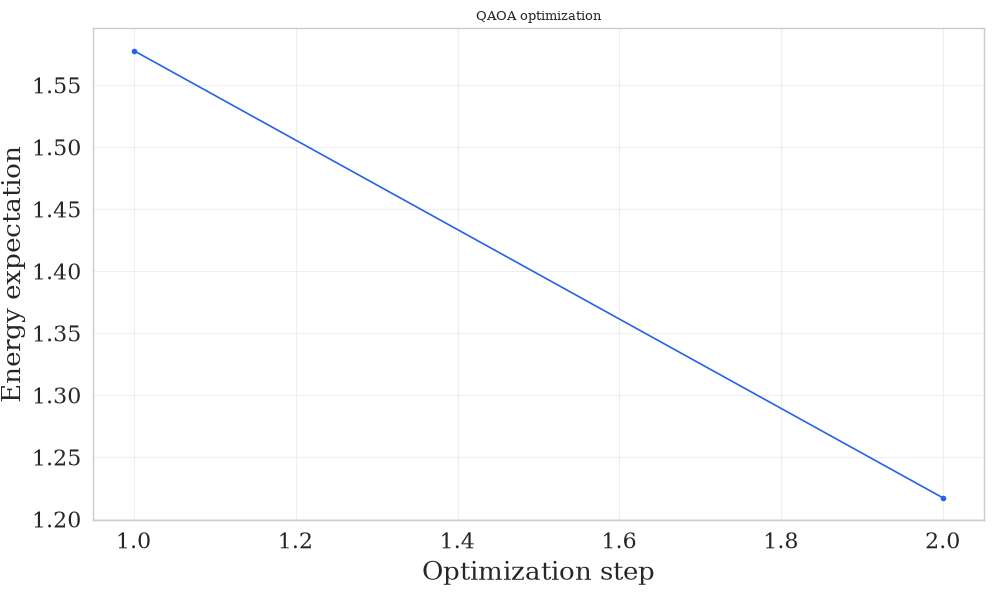

In [9]:
with tempfile.TemporaryDirectory(prefix="gpu_qaoa_") as tmp:
    save_config = dict(gpu_config)
    save_config["save"] = {
        "path": str(Path(tmp) / "results"),
        "atts": ["solution", "cut_value", "optimal_angles", "correlations", "state_representation"],
        "filename": "gpu_notebook",
        "save_original_data": [],
        "makedir": True,
        "savedir": True,
    }
    saved = tools.save_result(solver, save_config["save"])
    loaded = tools.load_result(saved.primary)
    print("saved:", saved.primary)
    print("loaded algorithm:", loaded.get("algorithm_type"))
    assert loaded.get("algorithm_type") == "qaoa_gpu"
    figure = tools.plot_optimization(solver) if solver.optimizer_history else None
    print("plot:", type(figure).__name__ if figure is not None else "no history")

## Итог

In [10]:
print("version:", QA_max_cut_lib.__version__)
print("GPU:", info["name"], "CC", info["compute_capability"])
print("full/pair CPU agreement: ok")
print("five criteria: ok")
print("sampler orientations: ok")
print("GPU RQAOA/LS: ok")

version: 0.1.0a6
GPU: NVIDIA GeForce RTX 3050 Laptop GPU CC [8, 6]
full/pair CPU agreement: ok
five criteria: ok
sampler orientations: ok
GPU RQAOA/LS: ok
